# 07 · Claim-level data: building triangles, inflation and large losses

**Question this notebook answers:** what changes when you have individual claims rather than a ready-made triangle, and how should a reserve respond to an **inflation shock** and to **large losses**?

### Why a second dataset

Schedule P is aggregate. It can't show claim counts, individual large claims, or the timing of each payment, which are exactly what's needed for large-loss and inflation work. Real claim-level reserving extracts are confidential and essentially never published, so I use **SPLICE** (Avanzi, Taylor & Wang; R package on CRAN, built on SynthETIC by Avanzi, Taylor, Wang & Wong). It's a peer-reviewed simulator that produces what a claims system extract looks like:

* one row per **transaction**: payments and case-estimate revisions, each timestamped
* claim **occurrence, notification and settlement** dates
* **notification and settlement delays that depend on claim size**: large claims take longer to settle and dominate the tail

The scenario (`data/generate_splice.R`, SPLICE complexity 4, fixed seed):

* ~600 claims a year for 10 accident years, labelled **2015-2024**, valued at **31/12/2024**
* base claims inflation of ~2% a year throughout
* **from mid-2022, an extra 10% a year of superimposed inflation on every payment**, mirroring the claims-inflation spike UK and US motor insurers experienced from 2022 (used-car and repair costs, labour, credit hire)

Because the simulator also produces **every future transaction**, we know the true outstanding liability and can score each method exactly. Amounts are in £ (synthetic).

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from reserving import config as cfg, data as D, plots as PL

PL.setup()
pd.options.display.float_format = "{:,.3f}".format
pd.options.display.width = 140

In [2]:
from reserving.factors import average_factors, cdfs
from reserving.methods import chain_ladder, summarise
from reserving.diagnostics import closure_rate, average_case_reserve
from reserving.large_loss import (inflation_index, to_real_terms, project_nominal, inflation_adjusted_cape_cod,
                                  payment_inflation_index, capped_triangles, large_loss_load)
from reserving.triangle import Triangle

claims, txns = D.load_splice()
print(f"{len(claims):,} claims, {len(txns):,} transactions")
claims[["claim_no", "ay", "occurrence_time", "notidel", "setldel", "claim_size", "no_payment"]].head()

5,905 claims, 53,724 transactions


,claim_no,ay,occurrence_time,notidel,setldel,claim_size,no_payment
0,1,2015,0.990,0.843,16.114,"117,267.738",11.000
1,2,2015,0.587,1.956,33.146,"1,302,007.725",4.000
2,3,2015,0.251,3.185,1.721,"8,559.582",3.000
3,4,2015,0.099,1.017,2.587,"8,766.175",2.000
4,5,2015,0.331,2.084,17.213,"270,547.922",17.000


In [3]:
print("One claim's transaction history (first 12 rows)")
txns.loc[txns["claim_no"] == txns["claim_no"].iloc[0], ["claim_no", "ay", "txn_time", "txn_type", "incurred", "case_os", "cumpaid"]].head(12)

One claim's transaction history (first 12 rows)


,claim_no,ay,txn_time,txn_type,incurred,case_os,cumpaid
0,1,2015,1.833,Ma,"12,874.665","12,874.665",0.000
1,1,2015,3.599,P,"12,874.665","10,757.921","2,116.743"
2,1,2015,5.578,Mi,"14,784.687","12,667.944","2,116.743"
3,1,2015,5.629,Mi,"19,214.013","17,097.270","2,116.743"
4,1,2015,5.731,P,"19,214.013","14,673.168","4,540.845"
5,1,2015,7.013,PMi,"21,700.548","14,521.012","7,179.536"
6,1,2015,8.278,P,"21,700.548","11,919.153","9,781.395"
7,1,2015,9.847,P,"21,700.548","9,086.999","12,613.549"
8,1,2015,11.254,PMi,"23,420.208","8,142.709","15,277.499"
9,1,2015,13.210,Mi,"22,668.094","7,390.595","15,277.499"


Transaction types: **Ma / Mi** = major / minor revision of the case estimate, **P** = payment, **PMi / PMa** = payment with a simultaneous revision. `incurred` = cumulative paid + case estimate after each transaction.

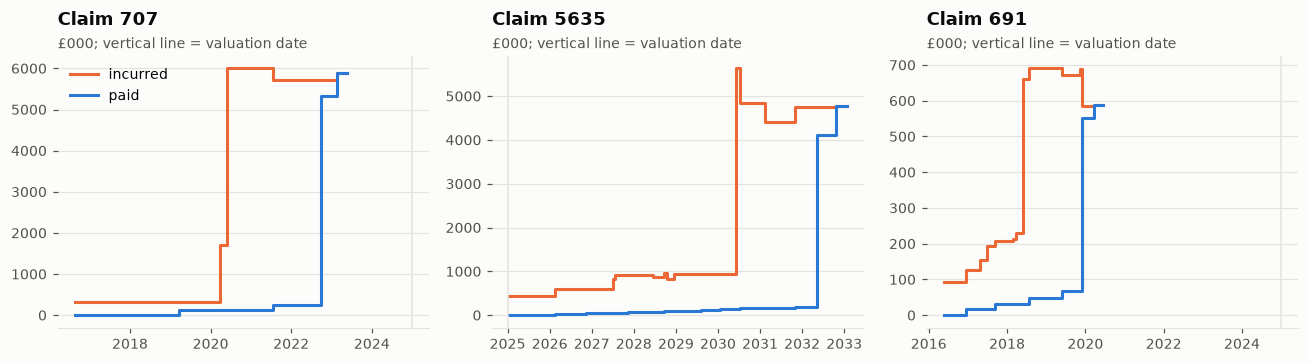

In [4]:
big = claims.sort_values("claim_size", ascending=False).iloc[[0, 40, 400]]["claim_no"].tolist()
fig, axes = plt.subplots(1, 3, figsize=(12, 3.4), sharey=False)
for ax, cn in zip(axes, big):
    h = txns[txns["claim_no"] == cn]
    t = np.r_[h["txn_time"].values, h["txn_time"].values[-1] + 1] / 4 + 2015
    inc = np.r_[h["incurred"].values, h["incurred"].values[-1]]
    pdn = np.r_[h["cumpaid"].values, h["cumpaid"].values[-1]]
    ax.step(t, inc / 1e3, where="post", color=PL.COLOURS["incurred"], label="incurred")
    ax.step(t, pdn / 1e3, where="post", color=PL.COLOURS["paid"], label="paid")
    ax.axvline(2025, color=PL.GRID, lw=1)
    ax.set_title(f"Claim {cn}")
    PL.subtitle(ax, "£000; vertical line = valuation date")
axes[0].legend()
fig.tight_layout()
PL.save(fig, "07_claim_histories")
plt.show()

The case estimate leads, payments follow, and the two converge at settlement, often years after the valuation date for large claims.

## 1. From transactions to triangles

Every claim's cumulative paid and incurred are read off at each calendar year end (an as-of join on transaction time), then aggregated by accident year and development year. The same snapshots, carried beyond the valuation date, give the full square and the true ultimate.

In [5]:
snap = D.splice_snapshots(claims, txns, max_dev=25)
full = D.splice_triangles(snap, max_dev=25)
tri = D.splice_triangles(snap, max_dev=10)
P, I = tri["paid"].upper(), tri["incurred"].upper()
true_ult = D.splice_true_ultimate(claims, txns)
paid_latest = P.latest_diagonal()
true_unpaid = true_ult - paid_latest

# Reconciliation checks
t40 = txns[txns["txn_time"] <= 40].groupby("claim_no")["cumpaid"].max().sum()
recon = pd.Series({
    "paid at valuation: triangle diagonal": paid_latest.sum(),
    "paid at valuation: direct from transactions": t40,
    "true ultimate: full square at age 25": full["paid"].values[25].sum(),
    "true ultimate: final paid per claim": true_ult.sum(),
})
assert np.isclose(recon.iloc[0], recon.iloc[1]) and np.isclose(recon.iloc[2], recon.iloc[3])
recon.to_frame("£").style.format("{:,.0f}")

,£
paid at valuation: triangle diagonal,"677,733,659"
paid at valuation: direct from transactions,"677,733,659"
true ultimate: full square at age 25,"1,591,022,154"
true ultimate: final paid per claim,"1,591,022,154"


In [6]:
print("Cumulative paid (£m)")
(P.values / 1e6).style.format("{:,.1f}", na_rep="")

Cumulative paid (£m)


dev,1,2,3,4,5,6,7,8,9,10
origin,,,,,,,,,,
2015,0.4,5.6,17.0,31.3,53.3,75.0,90.0,99.4,101.6,102.6
2016,0.7,5.3,17.6,37.7,60.5,81.6,99.9,108.7,110.9,
2017,0.6,6.2,20.3,43.1,69.1,92.4,110.0,123.7,,
2018,0.6,5.9,16.8,37.4,58.4,81.6,94.7,,,
2019,0.6,8.0,19.1,43.4,72.2,94.8,,,,
2020,0.7,6.7,20.3,49.3,74.6,,,,,
2021,0.4,6.3,21.1,46.0,,,,,,
2022,0.6,7.3,22.2,,,,,,,
2023,0.6,7.5,,,,,,,,


## 2. Count-based diagnostics: the checks Schedule P couldn't support

Notebook 02 couldn't tell faster settlement from weaker case reserves because Schedule P has no claim counts. With claim-level data, the two **Berquist-Sherman** diagnostics are easy:

* **closure rate** (closed ÷ reported claims) by age: if it rises along the diagonals, settlement has sped up
* **average case reserve per open claim**: compare by age across accident years after allowing for inflation. A fall in real terms signals weaker case reserving

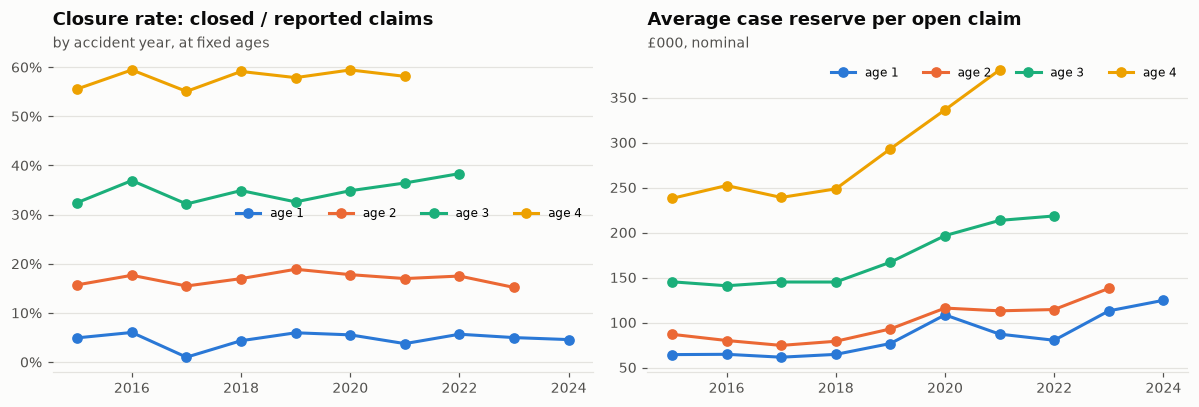

In [7]:
cr = closure_rate(tri["closed_count"].upper(), tri["reported_count"].upper())
acr = average_case_reserve(snap)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
ax = axes[0]
for age, col in zip([1, 2, 3, 4], PL.SERIES):
    s = cr[age].dropna(); ax.plot(s.index, s.values, marker="o", color=col, label=f"age {age}")
ax.set_title("Closure rate: closed / reported claims"); PL.subtitle(ax, "by accident year, at fixed ages"); PL.pct(ax); ax.legend(ncol=4, fontsize=8)
ax = axes[1]
for age, col in zip([1, 2, 3, 4], PL.SERIES):
    s = acr[age].dropna(); ax.plot(s.index, s.values / 1e3, marker="o", color=col, label=f"age {age}")
ax.set_title("Average case reserve per open claim"); PL.subtitle(ax, "£000, nominal"); ax.legend(ncol=4, fontsize=8)
fig.tight_layout()
PL.save(fig, "07_count_diagnostics")
plt.show()

* **Closure rates are flat across accident years.** Settlement speed hasn't changed, so the paid pattern itself is stable.
* **Average case reserves drift up steadily and then faster for recent years.** Case estimates are tracking cost inflation. A real-terms drop would have pointed to weaker case reserving, and there isn't one.

So unlike Penn National, here we can **rule out** settlement-speed and case-strength changes. Anything that breaks the chain ladder must be something else.

## 3. Detecting the inflation shock

A practical, data-only measure: the **geometric-mean payment** in each accident year × development age cell, compared with the same age one accident year earlier. Same age means a similar claim mix, and successive accident years are one calendar year apart, so the change estimates calendar-year inflation. (The geometric mean stops a few very large payments dominating.)

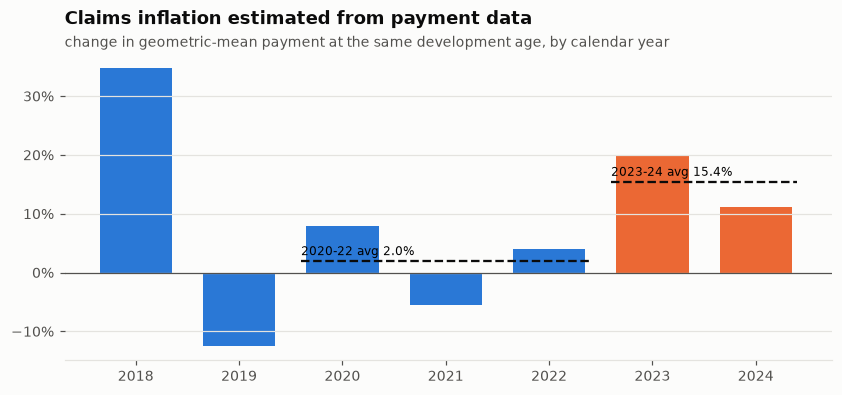

,inflation,cells,payments,index
cal,,,,
2018,34.7%,3,"1,715",3.338
2019,-12.4%,4,"2,368",2.923
2020,8.0%,5,"2,664",3.156
2021,-5.6%,6,"2,854",2.980
2022,3.9%,7,"2,933",3.098
2023,20.0%,7,"3,022",3.717
2024,11.1%,7,"2,991",4.128


In [8]:
pi = payment_inflation_index(txns, D.SPLICE_FIRST_YEAR, cfg.SPLICE_VALUATION)
pre = np.exp(np.log(1 + pi.loc[2020:2022, "inflation"]).mean()) - 1
post = np.exp(np.log(1 + pi.loc[2023:2024, "inflation"]).mean()) - 1
fig, ax = plt.subplots(figsize=(9, 3.6))
v = pi.loc[2018:, "inflation"]
ax.bar(v.index, v.values, color=[PL.SERIES[1] if y >= 2023 else PL.SERIES[0] for y in v.index], width=0.7)
ax.axhline(0, color=PL.INK_2, lw=0.8)
ax.hlines(pre, 2019.6, 2022.4, color=PL.INK, lw=1.5, ls="--"); ax.text(2019.6, pre + 0.01, f"2020-22 avg {pre:.1%}", fontsize=8)
ax.hlines(post, 2022.6, 2024.4, color=PL.INK, lw=1.5, ls="--"); ax.text(2022.6, post + 0.01, f"2023-24 avg {post:.1%}", fontsize=8)
ax.set_title("Claims inflation estimated from payment data")
PL.subtitle(ax, "change in geometric-mean payment at the same development age, by calendar year")
PL.pct(ax)
PL.save(fig, "07_inflation_detection")
plt.show()
pi.loc[2018:].style.format({"inflation": "{:.1%}", "cells": "{:.0f}", "payments": "{:,.0f}", "index": "{:.3f}"})

Year-to-year estimates are noisy (single years range from about −6% to +20%), but the averages are clear: **~2% a year before 2023 and ~15% after**. In practice an actuary would combine this with external indices (e.g. ONS / ABI motor claims inflation) rather than rely on a noisy internal series.

**Inflation assumption used below:** 2% a year up to 2022 and **12.2% a year from 2023** (2% base plus 10% superimposed, compounded). That's the external view, and the data check above is consistent with it. Future inflation is the key assumption, so it's tested explicitly.

## 4. What the naive chain ladder gets wrong

In [9]:
naive = {
    "CL paid": chain_ladder(P, cdfs(average_factors(P))),
    "CL incurred": chain_ladder(I, cdfs(average_factors(I))),
}
res = summarise(naive, paid_latest)["unpaid"]
res["True"] = true_unpaid
(res / 1e6).assign(**{"CL paid error": res["CL paid"] / res["True"] - 1}).style.format("{:,.1f}").format("{:.0%}", subset=["CL paid error"])

,CL paid,CL incurred,True,CL paid error
origin,,,,
2015,0.0,0.2,0.2,-100%
2016,1.1,2.5,2.6,-57%
2017,3.9,8.9,9.6,-60%
2018,13.3,18.0,15.5,-14%
2019,34.3,38.6,41.9,-18%
2020,63.2,83.6,79.4,-20%
2021,90.1,119.6,116.5,-23%
2022,121.3,143.9,161.9,-25%
2023,138.8,193.1,214.7,-35%


The **paid chain ladder falls ~30% short**. Its factors are averages of development that mostly happened at 2% inflation. Future payments will be made at 12% inflation, and the CL has no way to know. This is the reserving problem many motor teams faced in 2022-23.

The **incurred CL** does much better because case handlers have been revising estimates upward as costs rose, but it's still ~9% short. Case estimates don't fully anticipate *future* inflation on claims that will take years to settle.

## 5. Inflation-adjusted chain ladder

1. Deflate each past incremental payment to 2024 money using the index for its calendar year.
2. Project in real terms, where the development pattern should be stable.
3. Re-inflate each future payment to the year it will be paid, at an assumed future inflation rate.

In [10]:
rates = {y: (0.0 if y == 2015 else 0.02 if y <= 2022 else 0.122) for y in range(2015, 2025)}
idx = inflation_index(rates, base_year=cfg.SPLICE_VALUATION)
R = to_real_terms(P, idx)
f_real = average_factors(R)
exposure = pd.Series(cfg.SPLICE_EXPOSURE, index=P.origins)

ia = {}
for fut in [0.02, 0.07, cfg.FUTURE_INFLATION]:
    ia[f"Infl-adj CL paid (future {fut:.0%})"] = project_nominal(R, f_real, cfg.SPLICE_VALUATION, fut)["unpaid"]
ia[f"Infl-adj Cape Cod paid (future {cfg.FUTURE_INFLATION:.0%})"] = inflation_adjusted_cape_cod(R, f_real, exposure, cfg.SPLICE_VALUATION, cfg.FUTURE_INFLATION)["unpaid"]
ia_df = pd.DataFrame(ia)
ia_tot = ia_df.sum().to_frame("total unpaid")
ia_tot["vs true"] = ia_tot["total unpaid"] / true_unpaid.sum() - 1
(ia_tot.assign(**{"total unpaid": ia_tot["total unpaid"] / 1e6})).style.format({"total unpaid": "£{:,.1f}m", "vs true": "{:+.0%}"})

,total unpaid,vs true
Infl-adj CL paid (future 2%),£597.0m,-35%
Infl-adj CL paid (future 7%),£691.5m,-24%
Infl-adj CL paid (future 12%),£805.6m,-12%
Infl-adj Cape Cod paid (future 12%),£851.2m,-7%


* Deflating and re-inflating at only 2% is **slightly worse** than doing nothing (−35%). Adjusting the past isn't enough; the result depends on the **future** inflation assumption.
* Assuming the shock persists (12.2%) closes most of the gap: about −12% instead of −31%.
* An **inflation-adjusted Cape Cod**, which pools the real cost per vehicle-year across accident years instead of leveraging the thin recent paid data, gets closest at about −7%.

The remaining shortfall comes from (a) development beyond the observed ages for the oldest years (no paid tail is applied here) and (b) process noise: claims are heavy-tailed, and a few late large settlements move the totals.

## 6. Large losses

Large claims distort link ratios: one big claim settling in one cell changes the factor applied to every accident year. The standard treatment is to:

1. **cap** every claim at a threshold (here £1m in 2024 money, indexed back for earlier years so "large" means the same in real terms)
2. develop the **capped (attritional)** triangle with the chain ladder, where it's more stable
3. **load for the excess** using frequency × severity pooled across years: expected large claims per exposure × average real excess, BF-style

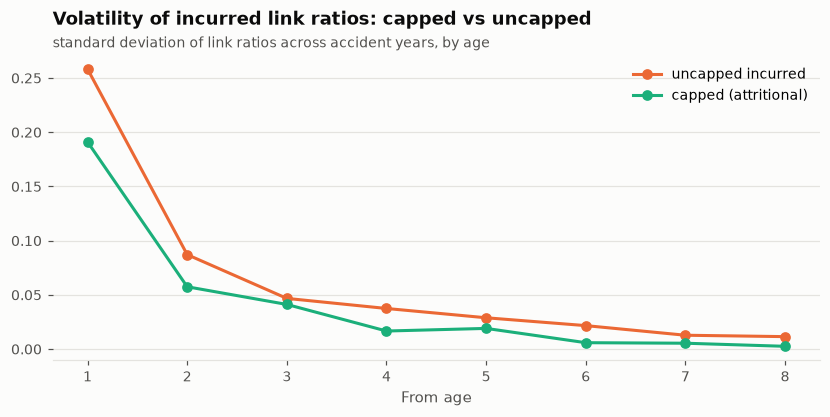

Large claims (> threshold) reported, by accident year: {2015: 24, 2016: 28, 2017: 43, 2018: 29, 2019: 40, 2020: 50, 2021: 37, 2022: 21, 2023: 15, 2024: 4}


In [11]:
obs = snap[snap["observed"]]
cap = capped_triangles(obs, cfg.LARGE_LOSS_THRESHOLD, idx)
vol = pd.DataFrame({
    "uncapped incurred": I.link_ratios().std(),
    "capped (attritional)": cap["capped"].link_ratios().std(),
    "excess layer": cap["excess"].link_ratios().replace([np.inf], np.nan).std(),
})
fig, ax = plt.subplots(figsize=(9, 3.6))
for col, c in zip(vol.columns[:2], [PL.COLOURS["incurred"], PL.SERIES[2]]):
    ax.plot(vol.index, vol[col], marker="o", color=c, label=col)
ax.set_title("Volatility of incurred link ratios: capped vs uncapped")
PL.subtitle(ax, "standard deviation of link ratios across accident years, by age")
ax.set_xlabel("From age"); ax.legend()
PL.save(fig, "07_capping_volatility")
plt.show()
print("Large claims (> threshold) reported, by accident year:", cap["large_count"].latest_diagonal().astype(int).to_dict())

In [12]:
A = cap["capped"]
ult_att = chain_ladder(A, cdfs(average_factors(A)))["ultimate"]
ll = large_loss_load(cap["large_count"], cap["excess"], exposure, idx)
ll_view = ll[["large_reported", "large_ultimate_count", "excess_reported", "excess_ultimate"]].copy()
ll_view[["excess_reported", "excess_ultimate"]] /= 1e6
print(f"Pooled real severity per large claim (excess over threshold): £{ll['severity_real'].iloc[0]/1e3:,.0f}k")
ll_view.style.format({"large_reported": "{:.0f}", "large_ultimate_count": "{:.1f}", "excess_reported": "£{:.1f}m", "excess_ultimate": "£{:.1f}m"})

Pooled real severity per large claim (excess over threshold): £767k


,large_reported,large_ultimate_count,excess_reported,excess_ultimate
origin,,,,
2015,24,24.0,£8.2m,£8.2m
2016,28,28.0,£18.3m,£18.2m
2017,43,43.8,£20.6m,£20.9m
2018,29,30.2,£16.3m,£17.1m
2019,40,42.5,£19.9m,£21.5m
2020,50,54.9,£35.0m,£39.3m
2021,37,47.7,£27.1m,£36.5m
2022,21,44.2,£17.2m,£34.6m
2023,15,48.7,£5.3m,£34.3m


Capping makes the attritional link ratios much steadier: volatility falls by a quarter to a third at ages 1-2 and by more than half from age 4. The large-loss load also handles the latest years properly. 2023 and 2024 have reported only 15 and 4 large claims so far, but the pooled frequency expects ~45 each eventually, so their excess layer is reserved at ~£34m each rather than £3-5m.

## 7. Scorecard against the true outcome

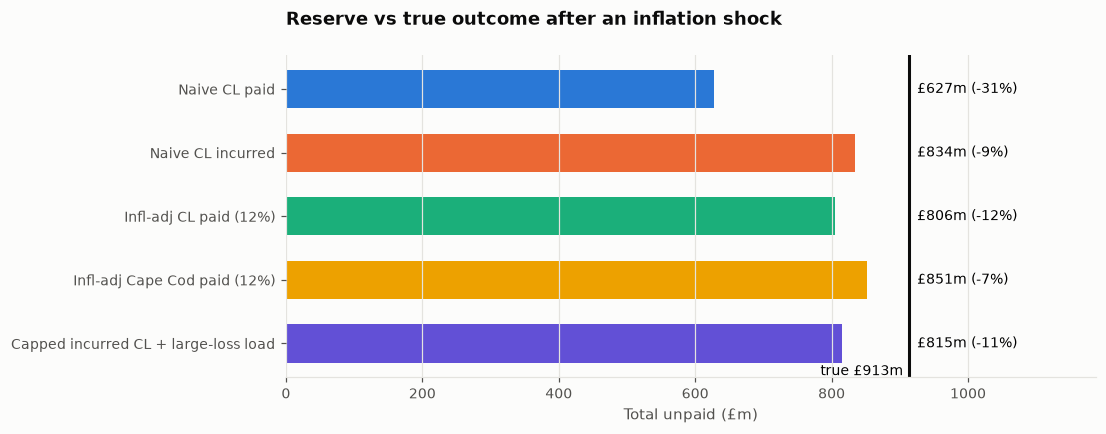

,total unpaid (£m),error vs true
Naive CL paid,627.0,-31.4%
Naive CL incurred,834.2,-8.7%
Infl-adj CL paid (12%),805.6,-11.8%
Infl-adj Cape Cod paid (12%),851.2,-6.8%
Capped incurred CL + large-loss load,815.1,-10.8%
True,913.3,+0.0%


In [13]:
score = pd.DataFrame({
    "Naive CL paid": res["CL paid"],
    "Naive CL incurred": res["CL incurred"],
    "Infl-adj CL paid (12%)": ia_df[f"Infl-adj CL paid (future {cfg.FUTURE_INFLATION:.0%})"],
    "Infl-adj Cape Cod paid (12%)": ia_df[f"Infl-adj Cape Cod paid (future {cfg.FUTURE_INFLATION:.0%})"],
    "Capped incurred CL + large-loss load": ult_att + ll["excess_ultimate"] - paid_latest,
    "True": true_unpaid,
})
tot = score.sum()
tbl = pd.DataFrame({"total unpaid (£m)": tot / 1e6, "error vs true": tot / tot["True"] - 1})
fig, ax = plt.subplots(figsize=(9.5, 3.8))
labels = tbl.index[:-1]
colors = [PL.SERIES[0], PL.SERIES[1], PL.SERIES[2], PL.SERIES[3], PL.SERIES[6]]
ax.barh(range(len(labels)), tbl["total unpaid (£m)"].iloc[:-1], color=colors, height=0.6)
ax.axvline(tbl.loc["True", "total unpaid (£m)"], color=PL.INK, lw=2)
true_v = tbl.loc["True", "total unpaid (£m)"]
ax.text(true_v - 8, len(labels) - 0.45, f"true £{true_v:,.0f}m", fontsize=9, ha="right", va="bottom")
for i, (v, e) in enumerate(zip(tbl["total unpaid (£m)"].iloc[:-1], tbl["error vs true"].iloc[:-1])):
    ax.text(max(v, true_v) + 12, i, f"£{v:,.0f}m ({e:+.0%})", va="center", fontsize=9)
ax.set_yticks(range(len(labels)), labels)
ax.invert_yaxis(); ax.grid(True, axis="x"); ax.grid(False, axis="y")
ax.set_xlim(0, tbl["total unpaid (£m)"].max() * 1.3)
ax.set_xlabel("Total unpaid (£m)")
ax.set_title("Reserve vs true outcome after an inflation shock")
PL.save(fig, "07_scorecard")
plt.show()
tbl.style.format({"total unpaid (£m)": "{:,.1f}", "error vs true": "{:+.1%}"})

## Lessons, and how they carry back to the main review

1. **Build triangles from transactions and reconcile them.** Done here to the penny. In practice, reconciling to the general ledger and the claims system is the first step of any reserve review.
2. **Claim counts let you test assumptions instead of guessing.** Closure rates and average case reserves settled here the exact question that stayed open for Penn National.
3. **An inflation shock breaks the paid chain ladder in a predictable direction (too low).** The fix is to model inflation explicitly. The future inflation rate is a key assumption that needs its own sensitivity testing and governance; adjusting only the past achieves nothing.
4. **Pooled, exposure-based methods (Cape Cod) are more robust for immature years**, in real terms as well as nominal. That matches the CAS back-test in notebook 06.
5. **Large-loss capping is about stability, not a cure-all.** It makes factors far less erratic and reserves recent years for large claims they haven't reported yet. But here the total (−11%) is no better than the naive incurred CL, because the binding problem is inflation and the capped projection is still in nominal terms. The natural next step is to **combine** the two (cap, deflate, project, load, re-inflate), which is how a production reserving model would treat a motor book after 2022.

For Penn National, notebook 02 found no calendar-year trend in the residuals, so no explicit inflation adjustment was needed there. Had there been one, sections 3-5 show how it would have been handled.